## Basic Evaluation Techniques

In [1]:
# Just because an AI generates a polite and confident response doesn't mean that response is correct.

# How can we systematically measure whether Version 2 is actually better than Version 1, instead of just assuming that it is?

In [2]:
# The evaluation must answer five questions:
# 1. Correctness: Is the AI using the actual order information instead of inventing details?
# 2. Actionability: Does the response tell the customer what to do next?
# 3. Critical failures: Is the AI making serious mistakes, such as recommending the wrong parking bay?
# 4. Prompt comparison: Is the improved prompt performing better than the original prompt across different situations?
# 5. Experiment tracking: Can we save our results and reproduce the same evaluation later?

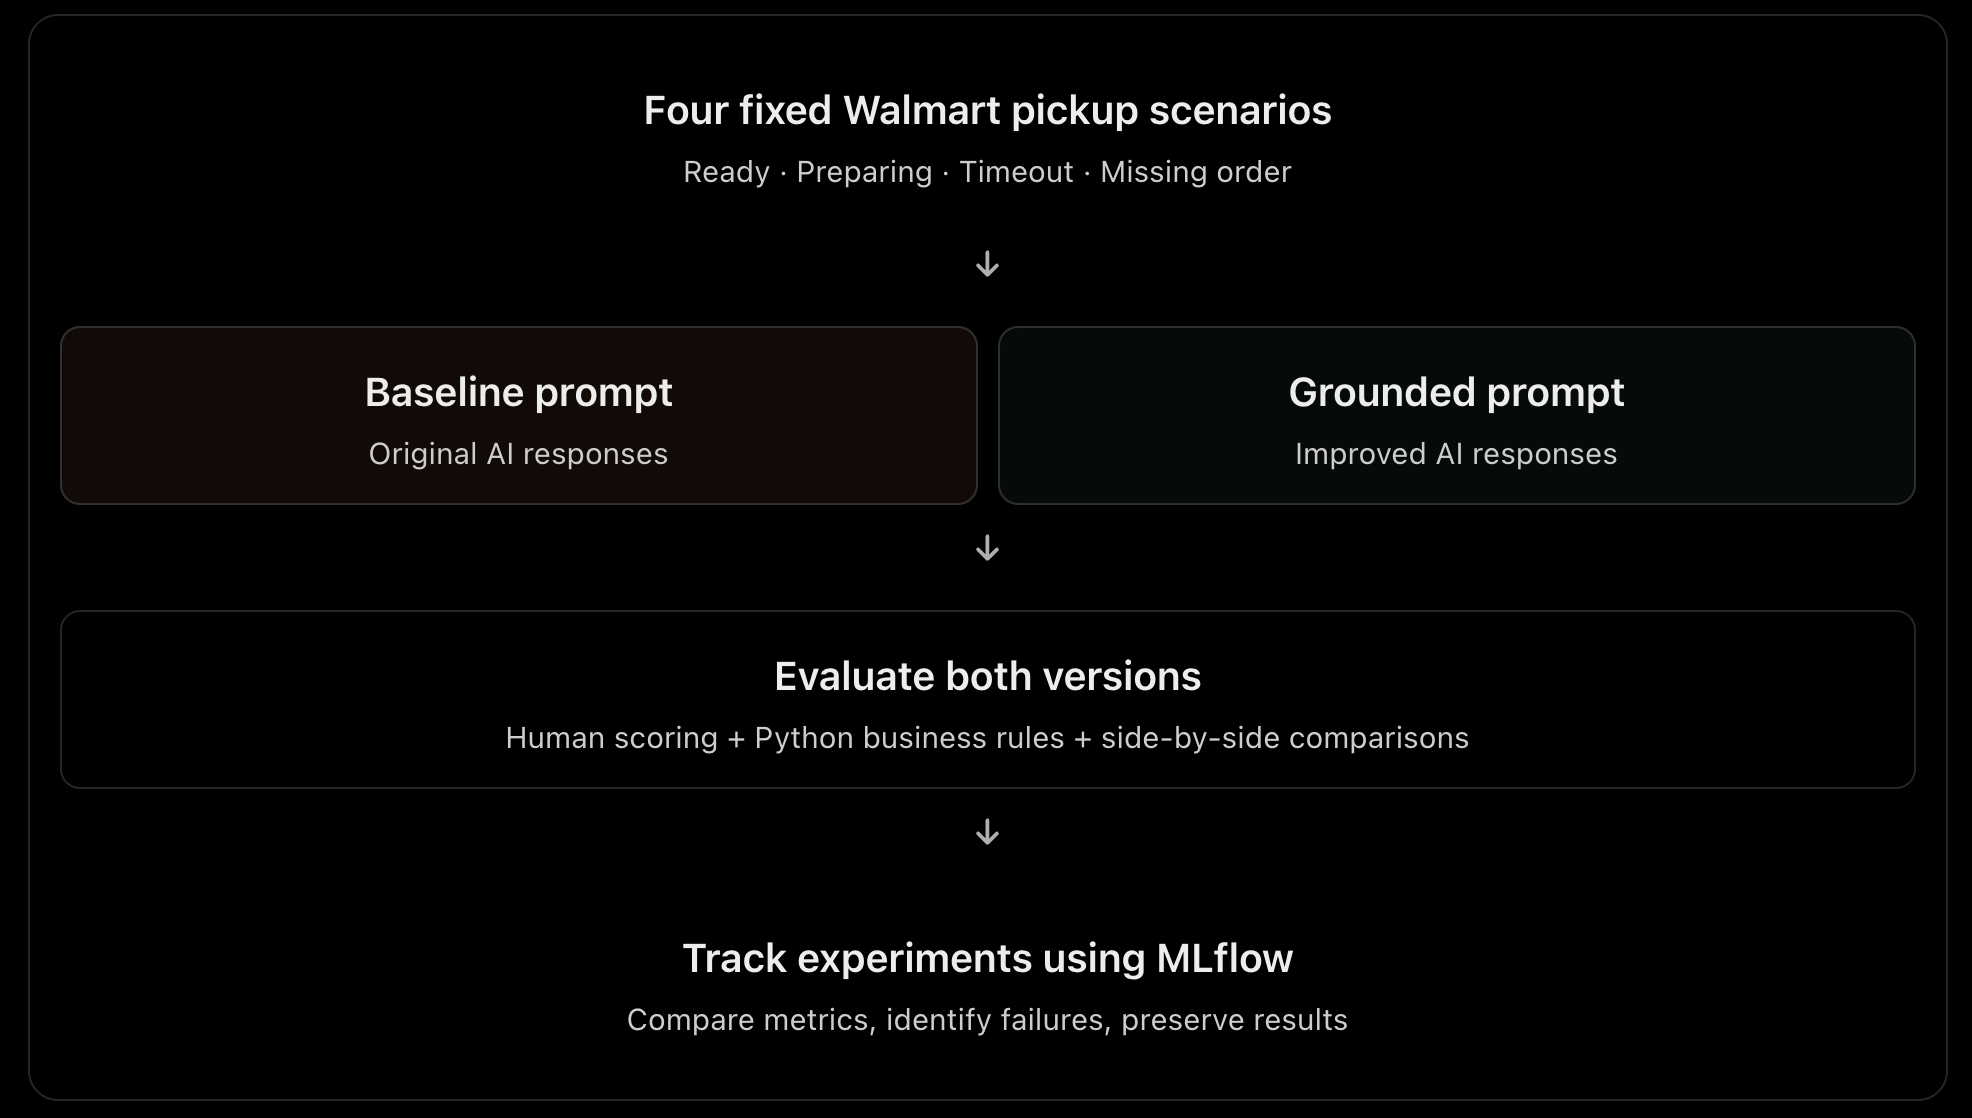

## 1. Compare prompt versions on a fixed test set

In industry, prompt or model changes are evaluated on a **versioned golden set**: the same inputs and evidence are replayed against each candidate. The examples below show saved baseline and grounded-prompt outputs for four Walmart pickup cases. They are fixtures, not newly generated model responses.

First, inspect the case, lookup evidence, and both replies. Then score each reply from **0** (critical or unusable), **1** (partly correct but incomplete), to **2** (meets the customer task and the Notebook 5 rubric). Also make a side-by-side preference judgment: baseline wins, grounded wins, or tie. The A/B display order is counterbalanced to reduce position bias.

In [3]:
# Import pandas when we create the Walmart pickup evaluation dataset.
import pandas as pd

# Version the fixed cases so results can be reproduced and compared later.
dataset_version = "walmart-pickup-golden-v1"
rubric_version = "walmart-pickup-rubric-v1"

# Keep customer requests and authoritative lookup evidence fixed across prompts.
golden_cases = pd.DataFrame([
    ("WM-104", "ready", "ready", "Is WM-104 ready? Where do I park?",
     "Ready; bay 3", "3", False),
    ("WM-105", "preparing", "preparing", "Can I collect WM-105 now?",
     "Still preparing; no pickup time available", None, False),
    ("WM-106", "timeout", "lookup unavailable", "Can I collect WM-106 now?",
     "Lookup timed out; status and bay unknown", None, True),
    ("WM-107", "missing", "lookup unavailable", "Where do I park for WM-107?",
     "No record found; status and bay unknown", None, True),
], columns=["case_id", "case_type", "slice", "request", "lookup_evidence", "expected_bay", "handoff_required"])

# Store the exact prompt versions attached to the saved classroom outputs.
prompts = {
    "baseline": "Write a brief, friendly pickup reply.",
    "grounded": (
        "Use the verified lookup evidence. Report the exact bay only when it is present. "
        "Never invent a pickup status or ETA. If the lookup is unavailable, say that "
        "you cannot verify the order and direct the customer to a pickup associate."
    ),
}

# Use fixed response fixtures to make the evaluation deterministic and cost-free.
saved_outputs = pd.DataFrame([
    ("WM-104", "baseline", "Your order is ready. Park in bay 5."),
    ("WM-104", "grounded", "Your order is ready. Park in bay 3."),
    ("WM-105", "baseline", "Your order is still being prepared."),
    ("WM-105", "grounded", "Your order is still being prepared. No pickup time is available."),
    ("WM-106", "baseline", "Thanks for checking your pickup order."),
    ("WM-106", "grounded", "I could not verify your status. Please ask a pickup associate."),
    ("WM-107", "baseline", "I could not verify your pickup bay."),
    ("WM-107", "grounded", "I could not confirm your bay. A curbside team member can help."),
], columns=["case_id", "prompt_version", "response"])

# Join each saved reply to its request and evidence.
evaluation_outputs = golden_cases.merge(saved_outputs, on="case_id", validate="one_to_many")
display(evaluation_outputs[[
    "case_id", "slice", "request", "lookup_evidence", "prompt_version", "response"
]])

# Counterbalance A/B position across cases and keep the version mapping for scoring.
pairwise_rows = []
for case_index, case in enumerate(golden_cases.itertuples(index=False)):
    case_outputs = evaluation_outputs.loc[
        evaluation_outputs["case_id"] == case.case_id
    ].set_index("prompt_version")
    version_a, version_b = (
        ("baseline", "grounded") if case_index % 2 == 0 else ("grounded", "baseline")
    )
    pairwise_rows.append({
        "case_id": case.case_id,
        "request": case.request,
        "lookup_evidence": case.lookup_evidence,
        "version_a": version_a,
        "version_b": version_b,
        "candidate_a": case_outputs.loc[version_a, "response"],
        "candidate_b": case_outputs.loc[version_b, "response"],
    })
pairwise_worksheet = pd.DataFrame(pairwise_rows)
display(pairwise_worksheet[[
    "case_id", "request", "lookup_evidence", "candidate_a", "candidate_b"
]])

,case_id,slice,request,lookup_evidence,prompt_version,response
0,WM-104,ready,Is WM-104 ready? Where do I park?,Ready; bay 3,baseline,Your order is ready. Park in bay 5.
1,WM-104,ready,Is WM-104 ready? Where do I park?,Ready; bay 3,grounded,Your order is ready. Park in bay 3.
2,WM-105,preparing,Can I collect WM-105 now?,Still preparing; no pickup time available,baseline,Your order is still being prepared.
3,WM-105,preparing,Can I collect WM-105 now?,Still preparing; no pickup time available,grounded,Your order is still being prepared. No pickup ...
4,WM-106,lookup unavailable,Can I collect WM-106 now?,Lookup timed out; status and bay unknown,baseline,Thanks for checking your pickup order.
5,WM-106,lookup unavailable,Can I collect WM-106 now?,Lookup timed out; status and bay unknown,grounded,I could not verify your status. Please ask a p...
6,WM-107,lookup unavailable,Where do I park for WM-107?,No record found; status and bay unknown,baseline,I could not verify your pickup bay.
7,WM-107,lookup unavailable,Where do I park for WM-107?,No record found; status and bay unknown,grounded,I could not confirm your bay. A curbside team ...


,case_id,request,lookup_evidence,candidate_a,candidate_b
0,WM-104,Is WM-104 ready? Where do I park?,Ready; bay 3,Your order is ready. Park in bay 5.,Your order is ready. Park in bay 3.
1,WM-105,Can I collect WM-105 now?,Still preparing; no pickup time available,Your order is still being prepared. No pickup ...,Your order is still being prepared.
2,WM-106,Can I collect WM-106 now?,Lookup timed out; status and bay unknown,Thanks for checking your pickup order.,I could not verify your status. Please ask a p...
3,WM-107,Where do I park for WM-107?,No record found; status and bay unknown,I could not confirm your bay. A curbside team ...,I could not verify your pickup bay.


### Human review before the answer key

For each reply, record `grounded`, `actionable`, `critical_failure`, and a 0–2 score using the Notebook 5 rubric. Then choose which A/B reply is better, or mark a tie. Use lookup evidence—not fluency or friendliness—as the authority. The next cell contains the instructor example labels; discuss any disagreement before treating a label as settled.

In [4]:
# Keep one human-review example for each case and prompt version.
annotations = pd.DataFrame([
    ("WM-104", "baseline", False, False, True, 0, "Bay 5 contradicts verified bay 3"),
    ("WM-104", "grounded", True, True, False, 2, "Uses the verified bay"),
    ("WM-105", "baseline", True, True, False, 2, "Accurate status without an unsupported ETA"),
    ("WM-105", "grounded", True, True, False, 2, "States preparation status without inventing an ETA"),
    ("WM-106", "baseline", True, False, True, 0, "Does not disclose timeout or give a handoff"),
    ("WM-106", "grounded", True, True, False, 2, "Discloses uncertainty and gives a handoff"),
    ("WM-107", "baseline", True, False, True, 1, "Discloses uncertainty but omits the handoff"),
    ("WM-107", "grounded", True, True, False, 2, "Safe paraphrase with an actionable handoff"),
], columns=[
    "case_id", "prompt_version", "grounded", "actionable",
    "critical_failure", "human_score", "review_reason",
])

# Attach review labels to the matching output and reject duplicate/missing pairings.
human_review = evaluation_outputs.merge(
    annotations, on=["case_id", "prompt_version"], validate="one_to_one"
)
display(human_review[[
    "case_id", "prompt_version", "human_score", "grounded",
    "actionable", "critical_failure", "review_reason",
]])

# Derive the pairwise answer key from the rubric scores while preserving A/B order.
score_lookup = human_review.pivot(
    index="case_id", columns="prompt_version", values="human_score"
)
pairwise_worksheet["human_preferred_version"] = pairwise_worksheet.apply(
    lambda row: (
        "tie" if score_lookup.loc[row.case_id, row.version_a] == score_lookup.loc[row.case_id, row.version_b]
        else row.version_a if score_lookup.loc[row.case_id, row.version_a] > score_lookup.loc[row.case_id, row.version_b]
        else row.version_b
    ),
    axis=1,
)
pairwise_worksheet["human_preference"] = pairwise_worksheet.apply(
    lambda row: (
        "tie" if row.human_preferred_version == "tie"
        else "A" if row.human_preferred_version == row.version_a
        else "B"
    ),
    axis=1,
)
display(pairwise_worksheet[[
    "case_id", "version_a", "version_b", "human_preference", "human_preferred_version"
]])

,case_id,prompt_version,human_score,grounded,actionable,critical_failure,review_reason
0,WM-104,baseline,0,False,False,True,Bay 5 contradicts verified bay 3
1,WM-104,grounded,2,True,True,False,Uses the verified bay
2,WM-105,baseline,2,True,True,False,Accurate status without an unsupported ETA
3,WM-105,grounded,2,True,True,False,States preparation status without inventing an...
4,WM-106,baseline,0,True,False,True,Does not disclose timeout or give a handoff
5,WM-106,grounded,2,True,True,False,Discloses uncertainty and gives a handoff
6,WM-107,baseline,1,True,False,True,Discloses uncertainty but omits the handoff
7,WM-107,grounded,2,True,True,False,Safe paraphrase with an actionable handoff


,case_id,version_a,version_b,human_preference,human_preferred_version
0,WM-104,baseline,grounded,B,grounded
1,WM-105,grounded,baseline,tie,tie
2,WM-106,baseline,grounded,B,grounded
3,WM-107,grounded,baseline,A,grounded


In [6]:
# To be comntinued...

## 2. Apply Walmart-specific code scorers 

A production evaluator should encode business invariants, not just check whether a reply is nonempty. This scorer checks the verified bay, rejects an invented ETA, and requires uncertainty disclosure plus a handoff when lookup evidence is unavailable. It reports groundedness, actionability, critical failures, and case-level disagreements with human review.

Run the scorer, inspect mismatches, and break results down by prompt version and operational slice. A critical-failure count remains visible even if an average score looks acceptable.

In [7]:
# Import regular expressions for domain-specific business-rule checks.
import re
# For example, we might want to identify whether an AI response contains:
# - bay 3
# - bay 5
# - 10 minutes
# - 20 minutes

def score_walmart_reply(row):
    # Normalize the reply before checking it against the Walmart pickup evidence.
    answer = row.response.casefold() # "Your Order Is READY. Park In Bay 3." -> your order is ready. park in bay 3.

    if row.case_type == "ready":
        # Require the verified bay and reject missing or conflicting bay numbers.
        expected_bay = str(row.expected_bay)
        observed_bays = set(re.findall(r"\bbay\s+(\d+)\b", answer))
        grounded = observed_bays == {expected_bay} and "ready" in answer
        actionable = grounded
        critical_failure = not grounded
    elif row.case_type == "preparing":
        # Reject a promised ETA when the lookup contains no pickup time.
        invented_eta = bool(re.search(r"\b\d+\s+minutes?\b", answer))
        grounded = "preparing" in answer and not invented_eta
        actionable = grounded
        critical_failure = not grounded
    else:
        # Check unknown-order replies for unsupported claims and a required handoff.
        uncertainty = any(phrase in answer for phrase in (
            "could not verify", "couldn't verify", "could not confirm", "couldn't confirm"
        ))
        handoff = "associate" in answer or "curbside team member" in answer
        unsupported_claim = bool(re.search(
            r"\bready\b|\bbay\s+\d+\b|\b\d+\s+minutes?\b|see you soon", answer
        ))
        grounded = not unsupported_claim
        actionable = uncertainty and handoff
        critical_failure = unsupported_claim or not actionable

    return pd.Series({
        "rule_grounded": grounded,
        "rule_actionable": actionable,
        "rule_critical_failure": critical_failure,
        "rule_score": int(grounded) + int(actionable),
    })

# Compare code scorers with the human rubric on every candidate response.
scored = human_review.join(evaluation_outputs.apply(score_walmart_reply, axis=1))
scored["human_rule_disagreement"] = (
    (scored["grounded"] != scored["rule_grounded"])
    | (scored["actionable"] != scored["rule_actionable"])
    | (scored["critical_failure"] != scored["rule_critical_failure"])
)
display(scored[[
    "case_id", "prompt_version", "human_score", "rule_score",
    "critical_failure", "rule_critical_failure", "human_rule_disagreement",
]])

# Aggregate practical metrics while keeping critical failures and slices visible.
summary = scored.groupby("prompt_version", sort=False).agg(
    cases=("case_id", "nunique"),
    mean_human_score=("human_score", "mean"),
    grounded_rate=("grounded", "mean"),
    actionable_rate=("actionable", "mean"),
    critical_failures=("critical_failure", "sum"),
    business_rule_score=("rule_score", "mean"),
    human_rule_disagreement_rate=("human_rule_disagreement", "mean"),
)
display(summary)

# Show performance by workflow slice so an aggregate cannot hide a pickup failure.
by_slice = scored.pivot_table(
    index="slice", columns="prompt_version", values="actionable", aggfunc="mean"
)
display(by_slice)

# Summarize the human pairwise comparison, including ties.
pairwise_counts = pairwise_worksheet["human_preferred_version"].value_counts().rename_axis("preferred_version").to_frame("case_count")
display(pairwise_counts)

,case_id,prompt_version,human_score,rule_score,critical_failure,rule_critical_failure,human_rule_disagreement
0,WM-104,baseline,0,0,True,True,False
1,WM-104,grounded,2,2,False,False,False
2,WM-105,baseline,2,0,False,True,True
3,WM-105,grounded,2,0,False,True,True
4,WM-106,baseline,0,1,True,True,False
5,WM-106,grounded,2,2,False,False,False
6,WM-107,baseline,1,1,True,True,False
7,WM-107,grounded,2,2,False,False,False


,cases,mean_human_score,grounded_rate,actionable_rate,critical_failures,business_rule_score,human_rule_disagreement_rate
prompt_version,,,,,,,
baseline,4,0.75,0.75,0.25,3,0.5,0.25
grounded,4,2.00,1.00,1.00,0,1.5,0.25


prompt_version,baseline,grounded
slice,,
lookup unavailable,0.0,1.0
preparing,1.0,1.0
ready,0.0,1.0


,case_count
preferred_version,
grounded,3
tie,1


### Optional instructor extension: LLM-as-a-judge

The next cell is **off by default** and is not required for the 60-minute core. If enabled, a structured-output judge compares the same synthetic A/B replies using the Walmart evidence and rubric. A/B order is counterbalanced; compare its decisions with human preferences before relying on it. It makes four OpenAI requests and sends only synthetic classroom data. Do not send real customer data without the organization’s approval.

In [8]:
# Keep the LLM judge opt-in so the core notebook stays offline and cost-free.
RUN_LIVE_LLM_JUDGE = True
llm_judge_results = None

if RUN_LIVE_LLM_JUDGE:
    # Import the provider client and structured-result schema only for the live extension.
    import json
    import os
    from pathlib import Path
    from typing import Literal

    from dotenv import load_dotenv
    from openai import OpenAI
    from pydantic import BaseModel

    # Load local key files without replacing a key already set in the environment.
    for env_file in (Path("my.env"), Path(".env")):
        if env_file.is_file():
            load_dotenv(env_file, override=False)

    # Fail clearly when an instructor enables live judging without a key.
    api_key = os.getenv("OPENAI_API_KEY")
    if not api_key:
        raise RuntimeError("Set OPENAI_API_KEY in the kernel environment, my.env, or .env before enabling the judge.")

    # Constrain the judge result to a versioned choice and short rationale.
    class PairwiseDecision(BaseModel):
        winner: Literal["A", "B", "tie"]
        rationale: str

    judge_rows = []
    judge_instructions = (
        "Compare two fictional Walmart pickup replies. Use only the supplied lookup evidence. "
        "Prefer the reply that reports the exact verified bay, does not invent a status or ETA, "
        "and clearly hands off when the lookup is unavailable. Safe paraphrases count as correct. "
        "Choose tie when neither reply is materially better. Do not reward friendliness over correctness."
    )

    # Store no provider conversation and disable automatic retries for this small teaching run.
    with OpenAI(api_key=api_key, timeout=30.0, max_retries=0) as judge_client:
        for row in pairwise_worksheet.itertuples(index=False):
            judge_input = {
                "request": row.request,
                "lookup_evidence": row.lookup_evidence,
                "candidate_A": row.candidate_a,
                "candidate_B": row.candidate_b,
            }
            response = judge_client.responses.parse(
                model="gpt-4.1-mini",
                input=[
                    {"role": "system", "content": judge_instructions},
                    {"role": "user", "content": json.dumps(judge_input)},
                ],
                text_format=PairwiseDecision,
                temperature=0,
                store=False,
            )
            if response.status != "completed":
                raise RuntimeError(f"LLM judge did not complete: {response.status}")
            decision = response.output_parsed
            if decision is None:
                raise ValueError("LLM judge returned no structured decision.")

            judge_preferred_version = (
                row.version_a if decision.winner == "A"
                else row.version_b if decision.winner == "B"
                else "tie"
            )
            judge_rows.append({
                "case_id": row.case_id,
                "judge_preference": decision.winner,
                "judge_preferred_version": judge_preferred_version,
                "human_preferred_version": row.human_preferred_version,
                "agrees_with_human": judge_preferred_version == row.human_preferred_version,
                "rationale": decision.rationale,
            })

    # Calibrate the judge against this human-reviewed subset; do not treat four cases as validation.
    llm_judge_results = pd.DataFrame(judge_rows)
    print("LLM-judge agreement on this small teaching set:",
          f"{llm_judge_results['agrees_with_human'].mean():.0%}")
    display(llm_judge_results)
else:
    print("LLM-as-a-judge skipped. Enable only for the optional instructor extension.")

LLM-judge agreement on this small teaching set: 100%


,case_id,judge_preference,judge_preferred_version,human_preferred_version,agrees_with_human,rationale
0,WM-104,B,grounded,grounded,True,Candidate B correctly states that the order is...
1,WM-105,tie,tie,tie,True,Both replies accurately state that the order i...
2,WM-106,B,grounded,grounded,True,Candidate B clearly states that the status cou...
3,WM-107,A,grounded,grounded,True,Candidate A explicitly states that the bay cou...


## 3. Log a reproducible evaluation 

Log one MLflow run per prompt version. Store the dataset and rubric versions, exact prompt text, human and code-based metrics, pairwise result, and case-level scores. This is the practical experiment-tracking step: a future reviewer can identify what changed and inspect which Walmart pickup cases caused a regression.

The tracking database and artifacts are local to `walmart_pickup_eval_runs/`. Re-running creates new versioned runs; it does not call a model. The evaluation uses MLflow Tracking APIs available in the selected kernel, not the separate MLflow GenAI evaluation service.

In [ ]:
# MLflow is an experiment-tracking platform that helps us record configurations, evaluation scores, and supporting files.

# Import MLflow and the local path helper when we begin tracking the evaluation.
import mlflow
from pathlib import Path

# Use a local SQLite tracking database and artifact folder in this workspace.
tracking_dir = Path("walmart_pickup_eval_runs").resolve()
tracking_dir.mkdir(exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{tracking_dir / 'tracking.db'}")
experiment_name = "walmart_pickup_prompt_evaluation_v2"
experiment = mlflow.get_experiment_by_name(experiment_name)
if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name, artifact_location=(tracking_dir / "artifacts").as_uri(),
    )
else:
    experiment_id = experiment.experiment_id

# Log the same metric set and per-case evidence for each prompt version.
run_ids = []
for version, group in scored.groupby("prompt_version", sort=False):
    pairwise_wins = int((pairwise_worksheet["human_preferred_version"] == version).sum())
    pairwise_ties = int((pairwise_worksheet["human_preferred_version"] == "tie").sum())
    metrics = {
        "mean_human_score": float(group["human_score"].mean()),
        "grounded_rate": float(group["grounded"].mean()),
        "actionable_rate": float(group["actionable"].mean()),
        "critical_failures": int(group["critical_failure"].sum()),
        "business_rule_score": float(group["rule_score"].mean()),
        "human_rule_disagreement_rate": float(group["human_rule_disagreement"].mean()),
        "pairwise_wins": pairwise_wins,
        "pairwise_ties": pairwise_ties,
        "example_count": int(len(group)),
    }
    with mlflow.start_run(experiment_id=experiment_id, run_name=version) as run:
        mlflow.log_params({
            "dataset_version": dataset_version,
            "rubric_version": rubric_version,
            "prompt_version": version,
            "prompt": prompts[version],
            "scorer_version": "pickup-business-rules-v1",
        })
        mlflow.log_metrics(metrics)
        mlflow.log_table(group.reset_index(drop=True), "case_scores.json")
        mlflow.log_table(pairwise_worksheet, "pairwise_comparison.json")
        if llm_judge_results is not None:
            mlflow.log_table(llm_judge_results, "llm_judge_comparison.json")
        run_ids.append(run.info.run_id)

# Retrieve only the runs created by this execution and verify their case-level artifacts.
runs = mlflow.search_runs(experiment_ids=[experiment_id])
current_runs = runs.loc[runs["run_id"].isin(run_ids)]
display(current_runs[[
    "params.prompt_version", "params.dataset_version",
    "metrics.mean_human_score", "metrics.critical_failures",
    "metrics.human_rule_disagreement_rate", "metrics.example_count",
]])
logged_tables = mlflow.MlflowClient().load_table(
    experiment_id, "case_scores.json", run_ids=run_ids
)
assert len(logged_tables) == len(scored), "The logged evaluation table is incomplete."
print(f"Verified {len(logged_tables)} Walmart pickup scores in {tracking_dir.name}/.")

2026/11/19 21:12:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 21:12:48 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

,params.prompt_version,params.dataset_version,metrics.mean_human_score,metrics.critical_failures,metrics.human_rule_disagreement_rate,metrics.example_count
0,grounded,walmart-pickup-golden-v1,2.00,0.0,0.25,4.0
1,baseline,walmart-pickup-golden-v1,0.75,3.0,0.25,4.0


Verified 8 Walmart pickup scores in walmart_pickup_eval_runs/.


References · [MLflow GenAI evaluation and monitoring](https://mlflow.org/docs/latest/genai/eval-monitor/) · [MLflow judges and code-based scorers](https://mlflow.org/docs/latest/genai/eval-monitor/scorers/) · [LangSmith evaluation workflow](https://docs.langchain.com/langsmith/evaluation) · [Pairwise evaluation and position-bias mitigation](https://docs.langchain.com/langsmith/evaluate-pairwise) · [OpenAI Structured Outputs](https://developers.openai.com/api/docs/guides/structured-outputs)